# Machine Learning Midterm - Breast Cancer Wisconsin

This notebook covers Sections 1-10 for the Breast Cancer Wisconsin dataset. Shared functions are in `utils.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import utils

pd.set_option("display.max_columns", 50)
utils.make_folders()

DATASET = "breast_cancer"
display(utils.package_versions())

,package,version
0,python,3.14.3
1,numpy,2.5.4
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,scipy,1.18.1
5,matplotlib,3.11.2
6,seaborn,0.13.2


# 1. Loading the Dataset
## 1.1 Load the dataset from scikit-learn

In [2]:
X, y, class_names = utils.load_data(DATASET)
print("Loaded with load_breast_cancer()")

Loaded with load_breast_cancer()


### 1.2 Create the data frame (X and y are kept separate)

In [3]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)
print("Is the target inside X?", "target" in X.columns)
print("\nFeature names:", list(X.columns))
print("\nTarget labels:", sorted(int(v) for v in y.unique()))
print("Target names:", class_names)
display(X.head())

Shape of X: (569, 30)
Shape of y: (569,)
Is the target inside X? False

Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target labels: [0, 1]
Target names: ['malignant', 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
display(utils.class_table(y, class_names))

,label,class_name,n_samples,percent
0,0,malignant,212,37.26
1,1,benign,357,62.74


**Interpretation.** The dataset has 569 samples and 30 numerical features; the target is kept outside X. There are 212 malignant (class 0, 37.3%) and 357 benign (class 1, 62.7%) cases. The classes are moderately imbalanced, so the splits are stratified and macro-averaged metrics are used. Original labels are kept, and malignant (class 0) is the positive class when malignant-case errors are discussed.

## 2. Dataset Quality Checks
### 2.1 Missing values and duplicates

In [5]:
missing = utils.missing_table(X)
display(missing)
print("Total missing values:", int(missing["missing_count"].sum()))
print("Duplicate rows:", utils.count_duplicates(X, y))
print("No missing values and no duplicate rows, so no imputation is needed.")

,feature,missing_count
0,mean radius,0
1,mean texture,0
2,mean perimeter,0
3,mean area,0
4,mean smoothness,0
5,mean compactness,0
6,mean concavity,0
7,mean concave points,0
8,mean symmetry,0
9,mean fractal dimension,0


Total missing values: 0
Duplicate rows: 0
No missing values and no duplicate rows, so no imputation is needed.


### 2.2 Potential outliers (IQR rule and |z| > 3) - nothing is removed

In [6]:
outliers = utils.outlier_table(X)
display(outliers)
print("Features with at least one IQR outlier:", int((outliers["n_iqr_outliers"] > 0).sum()), "of", X.shape[1])

,feature,iqr_lower,iqr_upper,n_iqr_outliers,n_abs_z_gt_3
13,area error,-23.1600,86.2000,65,6
10,radius error,-0.1374,0.8486,38,7
12,perimeter error,-1.0205,5.9835,38,8
23,worst area,-337.7500,1937.0500,35,10
14,smoothness error,0.0007,0.0126,30,7
19,fractal dimension error,-0.0012,0.0080,28,10
15,compactness error,-0.0160,0.0615,28,12
18,symmetry error,0.0027,0.0360,27,11
3,mean area,-123.3000,1326.3000,25,8
29,worst fractal dimension,0.0405,0.1230,24,9


Features with at least one IQR outlier: 29 of 30


### 2.3 Data types

In [7]:
display(utils.dtype_table(X))
n_num = X.select_dtypes(include="number").shape[1]
print("Numerical features:", n_num, "| Categorical features:", X.shape[1] - n_num)

,feature,dtype
0,mean radius,float64
1,mean texture,float64
2,mean perimeter,float64
3,mean area,float64
4,mean smoothness,float64
5,mean compactness,float64
6,mean concavity,float64
7,mean concave points,float64
8,mean symmetry,float64
9,mean fractal dimension,float64


Numerical features: 30 | Categorical features: 0


**Interpretation.** There are no missing values and no duplicate rows. All 30 features are float64 (30 numerical, 0 categorical). 29 of 30 features have at least one IQR outlier; the most are in `area error` (65), `radius error` and `perimeter error` (38 each) and `worst area` (35). These are real large or irregular tumours, so they are kept. KNN and K-Means use Euclidean distance, so very large values such as `worst area` (up to 4254) can dominate the distance. GaussianNB's mean and variance estimates are pulled by extreme values. Decision trees only compare a feature with a threshold, so they are mostly robust to outliers.

## 3. Exploratory Data Analysis (EDA)
Sections 2-3 are descriptive only. They are not used to select features, fit preprocessing or remove samples.
### 3.1 Descriptive statistics

In [8]:
display(utils.describe_features(X))

,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


### 3.2 Class distribution and correlations

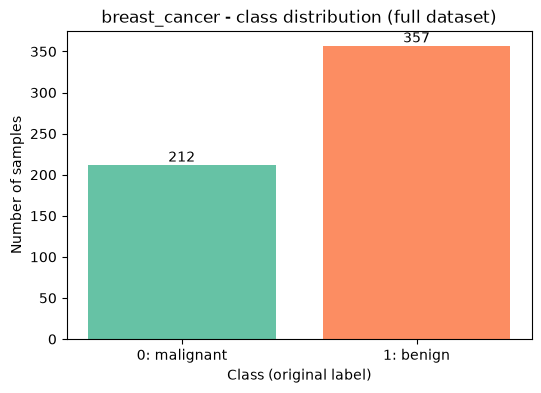

In [9]:
utils.plot_class_distribution(y, class_names, DATASET)

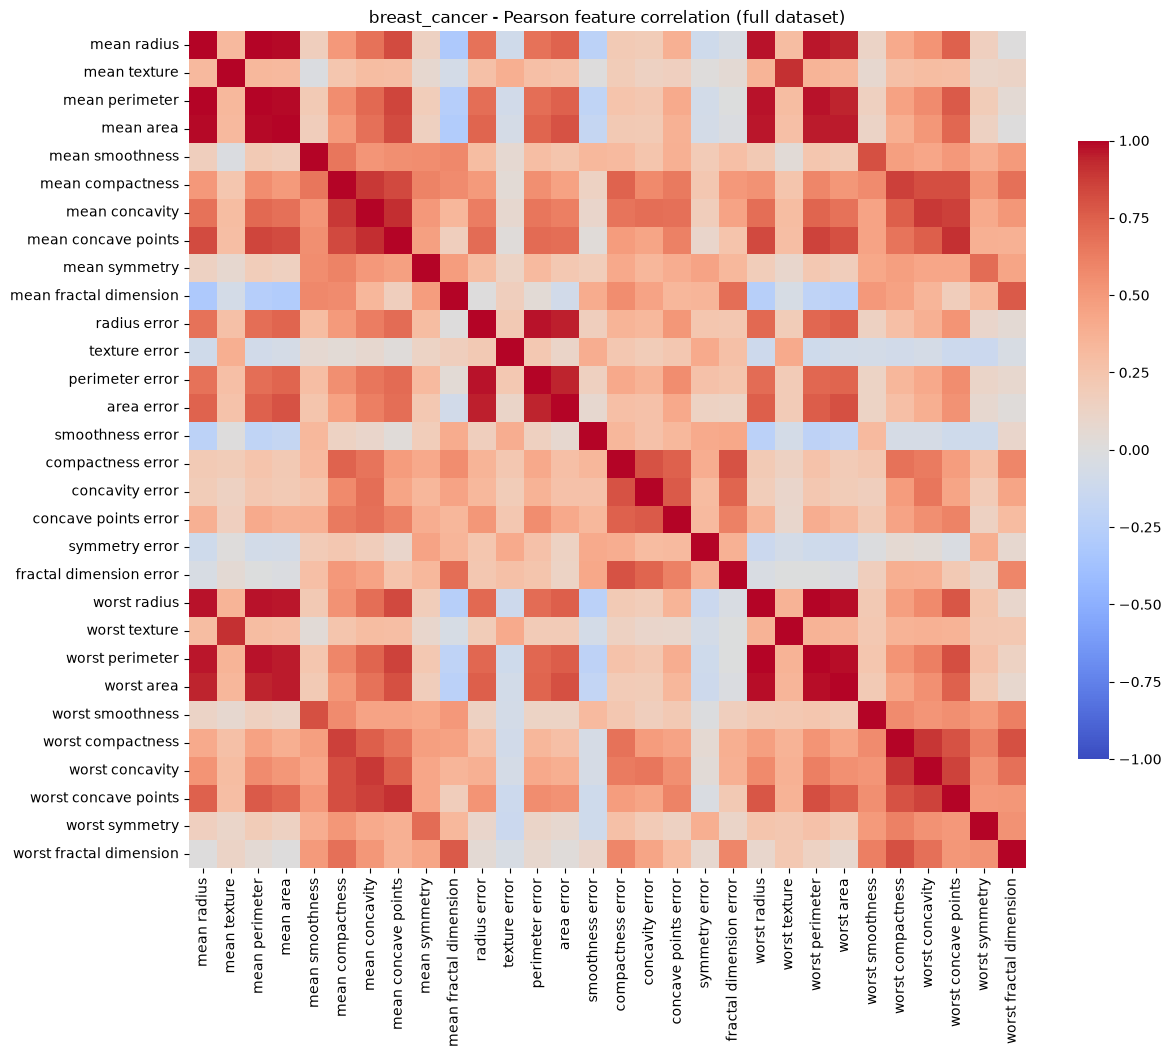

Three strongest unique feature pairs by |Pearson r|:


,feature_1,feature_2,pearson_r,abs_r
0,mean radius,mean perimeter,0.9979,0.9979
1,worst radius,worst perimeter,0.9937,0.9937
2,mean radius,mean area,0.9874,0.9874


In [10]:
corr = utils.plot_corr_heatmap(X, DATASET)
print("Three strongest unique feature pairs by |Pearson r|:")
display(utils.top_corr_pairs(corr, n=3))

### 3.3 Boxplots

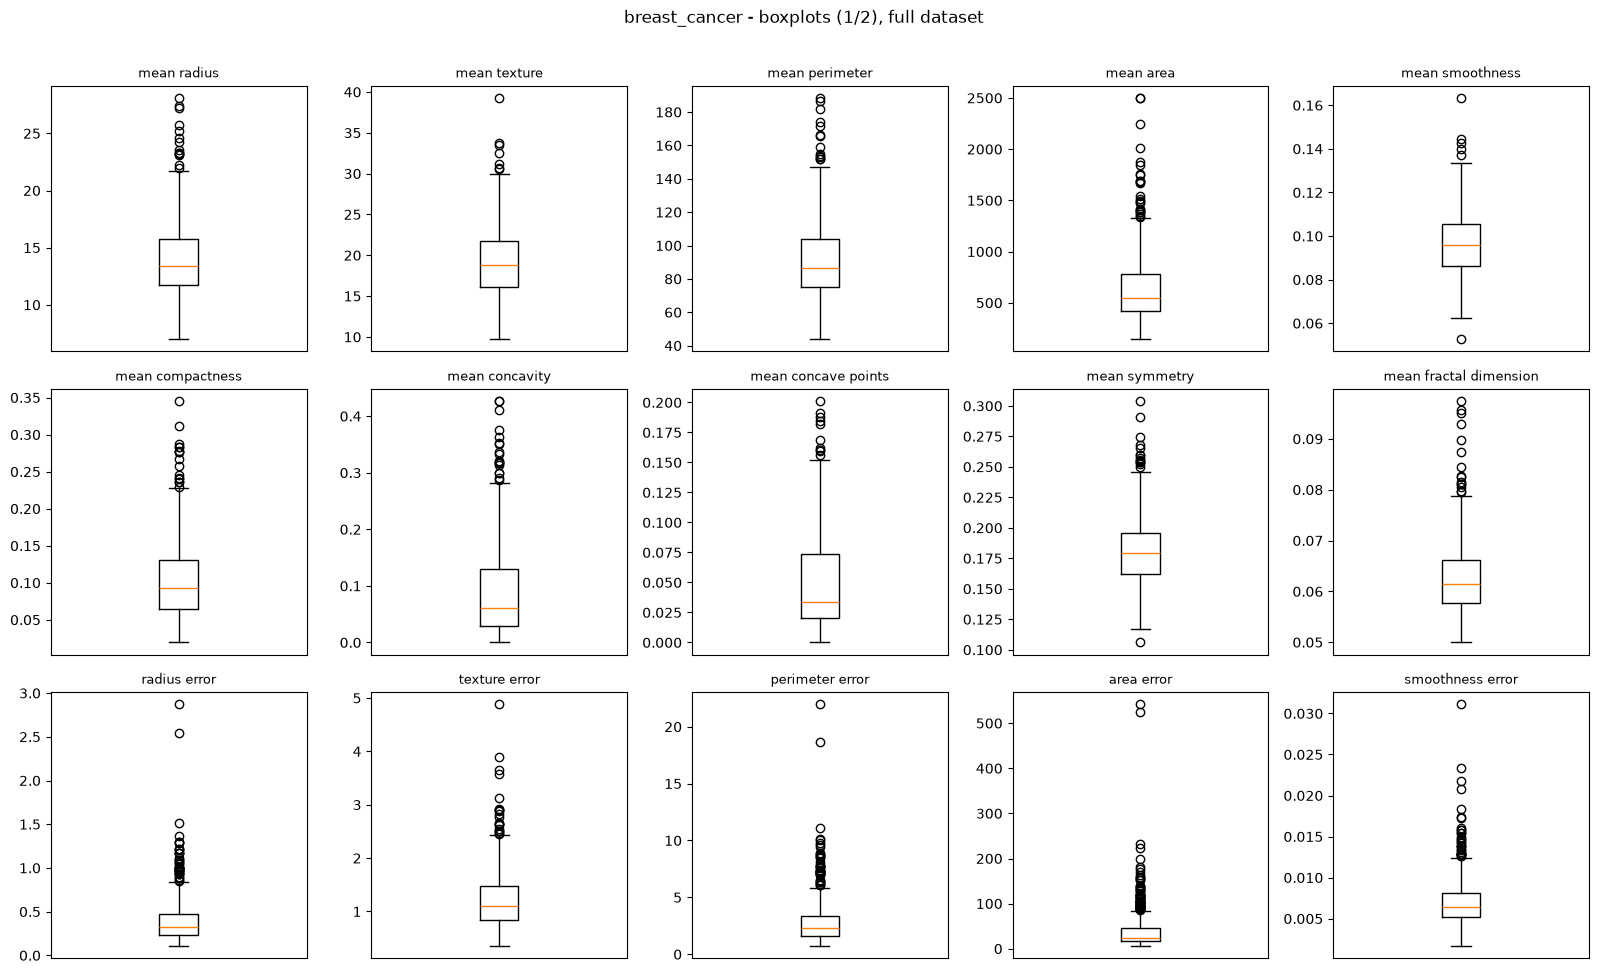

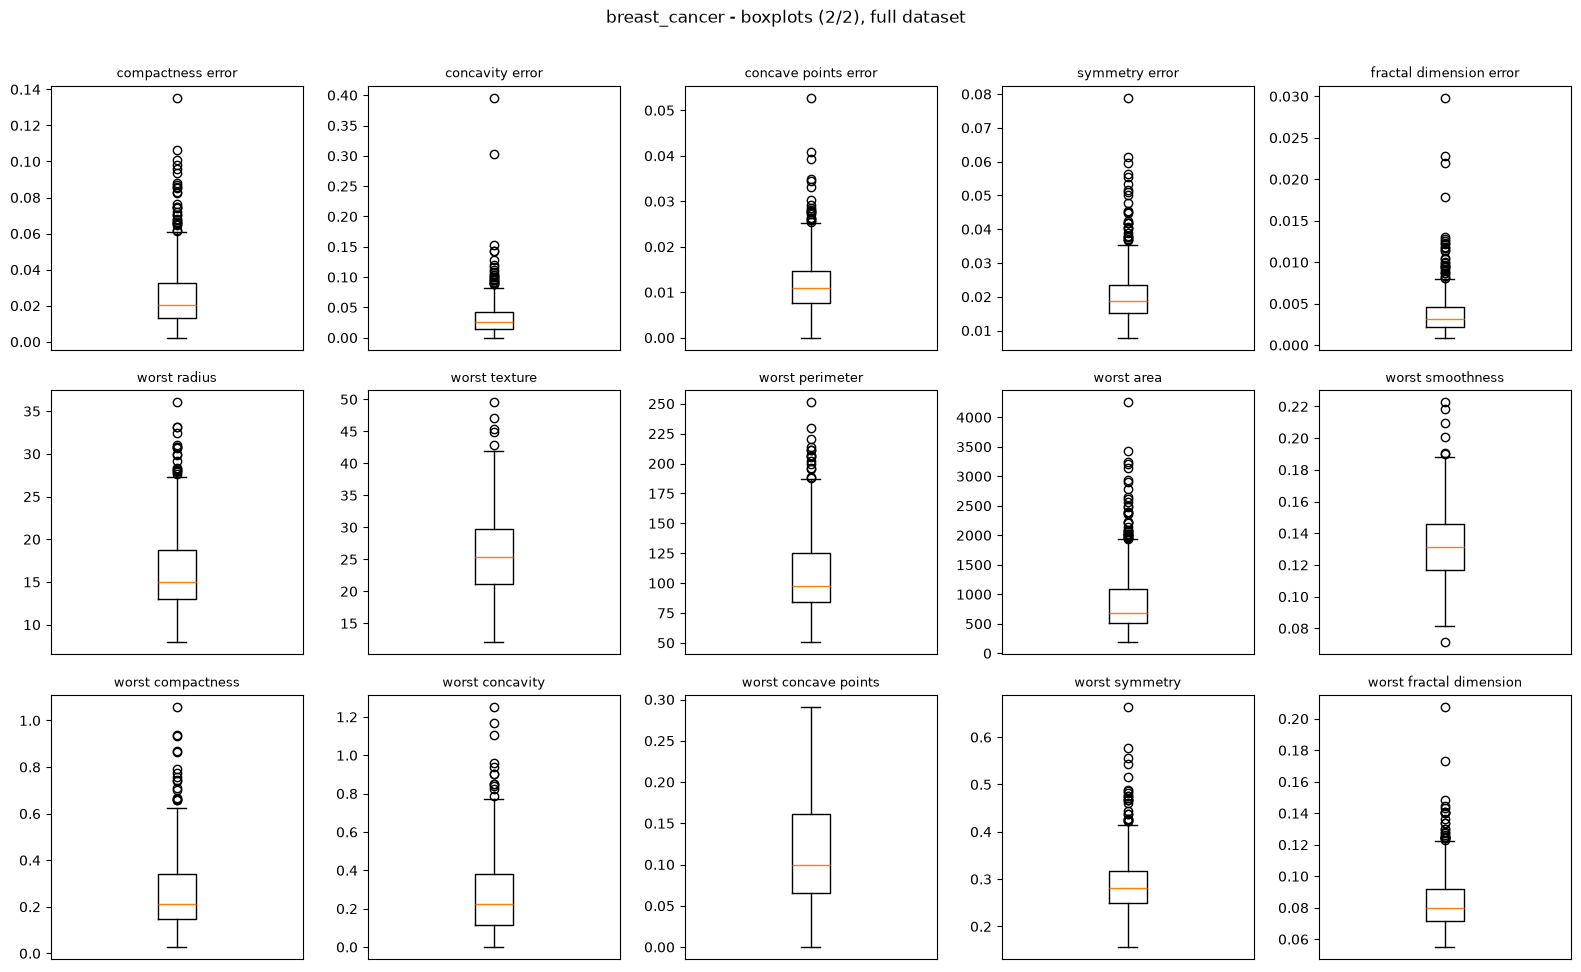

In [11]:
utils.plot_boxplots(X, DATASET, per_figure=15)

**Interpretation.** Feature scales differ a lot: `worst area` has a mean of 880.6, while `smoothness error` has a mean of 0.007. Several size features are right-skewed (for example, `mean area` has a mean of 654.9 and a median of 551.1). The three strongest pairs are `mean radius`-`mean perimeter` (r = 0.998), `worst radius`-`worst perimeter` (r = 0.994) and `mean radius`-`mean area` (r = 0.987). These are geometric relations: perimeter and area depend on the radius, so tumour size is counted several times in a distance. Boxplot observations: (1) the area and "error" features have long upper whiskers and many high outliers; (2) the concavity features start at 0 and are skewed upward.

## 4. Splitting the Dataset
### 4.1 Fixed test set + repeated training/validation split
1. The 20% test set is reserved **once** with `test_size=0.20, stratify=y, random_state=42`.
2. For each seed in [42, 52, 62] the remaining 80% is split with `test_size=0.125`, stratified, `random_state=seed` (0.125 x 80% = 10% of the full dataset).

In [12]:
splits, X_test, y_test = utils.make_splits(X, y)
for seed in utils.SEEDS:
    s = splits[seed]
    print(f"seed {seed}: X_train {s['X_train'].shape}, X_val {s['X_val'].shape}, X_test {X_test.shape}")

seed 42: X_train (398, 30), X_val (57, 30), X_test (114, 30)
seed 52: X_train (398, 30), X_val (57, 30), X_test (114, 30)
seed 62: X_train (398, 30), X_val (57, 30), X_test (114, 30)


### 4.2 Verify the split

In [13]:
print(f"Split summary for {DATASET} (3 subsets x 3 seeds = 9 rows):")
display(utils.split_summary(splits, y_test, len(X), class_names))
display(utils.check_splits(splits, X_test, len(X)))

same_test = all(
    set(X_test.index) == set(X.index) - set(splits[s]["X_train"].index) - set(splits[s]["X_val"].index)
    for s in utils.SEEDS)
print("Test indices identical across all three repetitions:", same_test)

Split summary for breast_cancer (3 subsets x 3 seeds = 9 rows):


,seed,subset,n,percent,class_0_malignant,class_1_benign
0,42,train,398,69.95,149,249
1,42,validation,57,10.02,21,36
2,42,test,114,20.04,42,72
3,52,train,398,69.95,149,249
4,52,validation,57,10.02,21,36
5,52,test,114,20.04,42,72
6,62,train,398,69.95,149,249
7,62,validation,57,10.02,21,36
8,62,test,114,20.04,42,72


,seed,train_val_overlap,train_test_overlap,val_test_overlap,total_rows,covers_full_dataset
0,42,0,0,0,569,True
1,52,0,0,0,569,True
2,62,0,0,0,569,True


Test indices identical across all three repetitions: True


In [14]:
idx_table, path = utils.save_split_indices(splits, X_test, DATASET)
show = idx_table[["seed", "subset", "n"]].copy()
show["first_10_indices"] = idx_table["original_row_indices"].str.split().str[:10]
display(show)
print("Full index lists saved to", path)

,seed,subset,n,first_10_indices
0,42,train,398,"[0, 2, 3, 4, 5, 6, 8, 9, 10, 11]"
1,42,validation,57,"[7, 13, 15, 27, 38, 39, 49, 50, 60, 66]"
2,42,test,114,"[1, 14, 20, 23, 24, 41, 51, 64, 70, 73]"
3,52,train,398,"[0, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
4,52,validation,57,"[13, 82, 87, 90, 98, 99, 111, 113, 123, 124]"
5,52,test,114,"[1, 14, 20, 23, 24, 41, 51, 64, 70, 73]"
6,62,train,398,"[0, 2, 3, 4, 5, 6, 7, 8, 9, 10]"
7,62,validation,57,"[26, 31, 33, 34, 36, 55, 61, 71, 72, 96]"
8,62,test,114,"[1, 14, 20, 23, 24, 41, 51, 64, 70, 73]"


Full index lists saved to results\breast_cancer_split_indices.csv


**Interpretation.** For every seed the split is 398 / 57 / 114 rows (69.95% / 10.02% / 20.04%). Because of stratification the class counts are the same for every seed: 149/249 in training, 21/36 in validation and 42/72 in testing. The seeds change which rows are in training and validation (the first validation indices differ), but the 114 test rows are identical in all three repetitions. There is no overlap between subsets and the three subsets always add up to 569 rows. Seed 42 is fixed in advance as the run used for the final test evaluation.

## 5. Data Preprocessing and Scaling
### 5.1 Missing values
Section 2 found **no missing values**, so no imputation step is added.
### 5.2 Selected scaler: StandardScaler
StandardScaler transforms every feature to z = (x - mean_train) / std_train. The same scaler type is used for both datasets and all three seeds.
### 5.3 Fit and apply the scaler correctly
A new scaler is fitted per seed on that seed's training features only (3 here, 6 across both datasets). Validation data are only transformed. The test set is transformed only with the seed-42 scaler.

In [15]:
reps, scalers, test_reps = utils.scale_data(splits, X_test)
for seed in utils.SEEDS:
    sc = scalers[seed]
    print(f"seed {seed}: scaler fitted on {int(sc.n_samples_seen_)} training rows; "
          f"first feature mean_train = {sc.mean_[0]:.4f}, std_train = {sc.scale_[0]:.4f}")

Xtr_s, _ = reps[42]["scaled"]
print("\nSeed-42 scaled training data: mean of every column ~ 0 ?",
      np.allclose(Xtr_s.mean().values, 0, atol=1e-9),
      "| std ~ 1 ?", np.allclose(Xtr_s.std(ddof=0).values, 1, atol=1e-9))

seed 42: scaler fitted on 398 training rows; first feature mean_train = 14.1113, std_train = 3.5524
seed 52: scaler fitted on 398 training rows; first feature mean_train = 13.9790, std_train = 3.4807
seed 62: scaler fitted on 398 training rows; first feature mean_train = 14.1072, std_train = 3.5604

Seed-42 scaled training data: mean of every column ~ 0 ? True | std ~ 1 ? True


In [16]:
print("Seed 42 - first five TRAINING rows BEFORE scaling:")
display(reps[42]["unscaled"][0].head())
print("Seed 42 - the same five TRAINING rows AFTER StandardScaler:")
display(reps[42]["scaled"][0].head().round(4))

Seed 42 - first five TRAINING rows BEFORE scaling:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.08451,0.10140,0.06830,0.03099,0.1781,0.06249,0.3642,1.0400,2.579,28.32,0.006530,0.03369,0.047120,0.014030,0.02740,0.004651,13.46,23.07,88.13,551.3,0.1050,0.2158,0.19040,0.07625,0.2685,0.07764
390,10.26,12.22,65.75,321.6,0.09996,0.07542,0.01923,0.01968,0.1800,0.06569,0.1911,0.5477,1.348,11.88,0.005682,0.01365,0.008496,0.006929,0.01938,0.002371,11.38,15.65,73.23,394.5,0.1343,0.1650,0.08615,0.06696,0.2937,0.07722
420,11.57,19.04,74.20,409.7,0.08546,0.07722,0.05485,0.01428,0.2031,0.06267,0.2864,1.4400,2.206,20.30,0.007278,0.02047,0.044470,0.008799,0.01868,0.003339,13.07,26.98,86.43,520.5,0.1249,0.1937,0.25600,0.06664,0.3035,0.08284
356,13.05,18.59,85.09,512.0,0.10820,0.13040,0.09603,0.05603,0.2035,0.06501,0.3106,1.5100,2.590,21.57,0.007807,0.03932,0.051120,0.018760,0.02860,0.005715,14.19,24.85,94.22,591.2,0.1343,0.2658,0.25730,0.12580,0.3113,0.08317
446,17.75,28.03,117.30,981.6,0.09997,0.13140,0.16980,0.08293,0.1713,0.05916,0.3897,1.0770,2.873,43.95,0.004714,0.02015,0.036970,0.011100,0.01237,0.002556,21.53,38.54,145.40,1437.0,0.1401,0.3762,0.63990,0.19700,0.2972,0.09075


Seed 42 - the same five TRAINING rows AFTER StandardScaler:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.4648,0.1768,-0.4675,-0.5187,-0.8838,-0.0733,-0.2806,-0.4667,-0.0768,-0.0693,-0.1311,-0.2897,-0.1268,-0.2652,-0.1787,0.4117,0.4137,0.3498,0.7268,0.2939,-0.5734,-0.3791,-0.5611,-0.5783,-1.2264,-0.2594,-0.4165,-0.5849,-0.3396,-0.3582
390,-1.0841,-1.5530,-1.0653,-0.9445,0.2505,-0.5540,-0.8688,-0.7525,-0.0096,0.3752,-0.7658,-1.1679,-0.7372,-0.6437,-0.4444,-0.6585,-0.7412,-0.7657,-0.1679,-0.5237,-1.0011,-1.5474,-1.0004,-0.8549,0.0699,-0.5730,-0.8928,-0.7236,0.0461,-0.3811
420,-0.7154,-0.0149,-0.7212,-0.6939,-0.8140,-0.5207,-0.4418,-0.8890,0.8065,-0.0443,-0.4164,0.4239,-0.3118,-0.4498,0.0557,-0.2943,0.3344,-0.4720,-0.2460,-0.1766,-0.6536,0.2366,-0.6112,-0.6326,-0.3460,-0.3959,-0.1167,-0.7284,0.1961,-0.0735
356,-0.2988,-0.1164,-0.2778,-0.4030,0.8555,0.4632,0.0517,0.1660,0.8206,0.2807,-0.3276,0.5488,-0.1214,-0.4206,0.2214,0.7123,0.5333,1.0928,0.8607,0.6755,-0.4233,-0.0988,-0.3815,-0.5079,0.0699,0.0492,-0.1108,0.1548,0.3155,-0.0555
446,1.0243,2.0126,1.0339,0.9325,0.2512,0.4817,0.9359,0.8458,-0.3170,-0.5319,-0.0375,-0.2237,0.0190,0.0947,-0.7476,-0.3114,0.1102,-0.1105,-0.9500,-0.4574,1.0861,2.0568,1.1275,0.9841,0.3265,0.7307,1.6376,1.2177,0.0997,0.3594


**Interpretation.** StandardScaler was chosen because KNN and K-Means use Euclidean distance; without scaling, large-valued features such as the area features would dominate the distance. After scaling, each feature is measured in standard deviations from its training mean. For example, training row 301 has `mean area` = 471.3, which becomes -0.52 (below the training mean), and row 446 has 981.6, which becomes +0.93. The three scalers have slightly different means for the first feature (14.111, 13.979, 14.107), which shows that each one was fitted only on its own seed's training rows. Validation and test data were never used to fit a scaler.

## 6. Preparing the Two Data Representations
* **Unscaled**: all original features (no imputation needed).
* **Scaled**: the same features and the same row indices after StandardScaler.

Both representations of a seed share exactly the same training and validation rows, so the only difference between them is scaling. No feature selection or dimensionality reduction is applied.

In [17]:
for seed in utils.SEEDS:
    (tr_u, va_u) = reps[seed]["unscaled"]
    (tr_s, va_s) = reps[seed]["scaled"]
    print(f"seed {seed}: same train rows = {tr_u.index.equals(tr_s.index)}, "
          f"same val rows = {va_u.index.equals(va_s.index)}, "
          f"features = {tr_u.shape[1]} / {tr_s.shape[1]}")

print("Test set: same rows =", test_reps["unscaled"].index.equals(test_reps["scaled"].index))

seed 42: same train rows = True, same val rows = True, features = 30 / 30
seed 52: same train rows = True, same val rows = True, features = 30 / 30
seed 62: same train rows = True, same val rows = True, features = 30 / 30
Test set: same rows = True


**Interpretation.** For every seed, the unscaled and scaled versions contain exactly the same training and validation rows and all 30 original features. The fixed test set also has the same rows in both versions (scaled with the seed-42 scaler). Any difference between the two representations in Section 7 is therefore caused by scaling only.

## 7.Training the Classification Models
### 7.1 Required experiments
Decision Tree(max_depth = 2, 3, 5, 10, None; random_state = seed), KNN (k = 1, 3, 5, 7, 11; uniform weights; Euclidean distance) and GaussianNB (default settings) are trained on both representations under all three seeds: (5 + 5 + 1) x 2 x 3 = **66 runs** for this dataset. Every model is fitted on training data only; all other settings stay at their defaults.

In [18]:
runs, models_42 = utils.train_all_models(DATASET, reps, splits)
print("Number of classifier runs:", len(runs))
print("Runs per algorithm:", runs["algorithm"].value_counts().to_dict())
print("Example run IDs:", runs["run_id"].head(3).tolist())
print("Seed-42 fitted models kept for the final evaluation:", len(models_42))

Number of classifier runs: 66
Runs per algorithm: {'decision_tree': 30, 'knn': 30, 'gaussian_nb': 6}
Example run IDs: ['breast_cancer_dt_unscaled_d2_s42', 'breast_cancer_dt_unscaled_d3_s42', 'breast_cancer_dt_unscaled_d5_s42']
Seed-42 fitted models kept for the final evaluation: 22


### 7.2 Run-level table (66 rows: 22 configurations x 3 seeds)
Each run records the training accuracy and training macro-F1, followed by the five validation metrics.

In [19]:
show_cols = ["run_id", "seed", "algorithm", "representation", "parameter", "parameter_value",
             "train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
             "val_macro_recall", "val_macro_f1", "val_roc_auc"]
pd.set_option("display.max_rows", 100)
display(runs[show_cols].round(4))

undef = runs[runs["val_undefined_metrics"] != "none"]
print("Runs with undefined precision/recall before zero_division replacement:", len(undef))

,run_id,seed,algorithm,representation,parameter,parameter_value,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,breast_cancer_dt_unscaled_d2_s42,42,decision_tree,unscaled,max_depth,2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,breast_cancer_dt_unscaled_d3_s42,42,decision_tree,unscaled,max_depth,3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,breast_cancer_dt_unscaled_d5_s42,42,decision_tree,unscaled,max_depth,5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,breast_cancer_dt_unscaled_d10_s42,42,decision_tree,unscaled,max_depth,10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,breast_cancer_dt_unscaled_dNone_s42,42,decision_tree,unscaled,max_depth,None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
5,breast_cancer_knn_unscaled_k1_s42,42,knn,unscaled,n_neighbors,1,1.0000,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393
6,breast_cancer_knn_unscaled_k3_s42,42,knn,unscaled,n_neighbors,3,0.9598,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160
7,breast_cancer_knn_unscaled_k5_s42,42,knn,unscaled,n_neighbors,5,0.9523,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299
8,breast_cancer_knn_unscaled_k7_s42,42,knn,unscaled,n_neighbors,7,0.9497,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511
9,breast_cancer_knn_unscaled_k11_s42,42,knn,unscaled,n_neighbors,11,0.9472,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550


Runs with undefined precision/recall before zero_division replacement: 0


**Interpretation.** All 66 runs were completed: 30 Decision Tree, 30 KNN and 6 GaussianNB fits. Every run has an ID containing the dataset, algorithm, representation, parameter and seed (for example `breast_cancer_knn_scaled_k5_s42`), and all runs are recorded, including the low-scoring ones. No validation run had a class with undefined precision or recall. The seed is part of the run ID; it is not a parameter to optimise. The 22 seed-42 models are kept for the final test evaluation.

## 8. Measuring Validation Performance
### 8.1 Metrics
Accuracy, macro precision, macro recall, macro F1 (`average="macro"`, `zero_division=0`) and ROC-AUC are calculated on each run's own validation subset. ROC-AUC uses the evaluation target 1 = malignant (original class 0) and the predicted probability of original class 0.
### 8.2 Summary across seeds (22 rows) and model selection
Mean and sample standard deviation (ddof=1) over seeds 42, 52 and 62. Selection rule: highest mean validation macro-F1, then mean validation accuracy, then lower macro-F1 std, then alphabetical configuration ID. Test results are never used.

In [20]:
summary = utils.summarize_runs(runs)
display(summary.round(4))

selected, ranked = utils.select_config(summary)
print("Top 5 configurations by the selection rule:")
display(ranked[["config_id", "val_macro_f1_mean", "val_macro_f1_std", "val_accuracy_mean"]].head(5).round(4))
SELECTED = selected["config_id"]
print("SELECTED CONFIGURATION:", SELECTED)

,dataset,config_id,algorithm,representation,parameter,parameter_value,train_accuracy_mean,train_accuracy_std,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_precision_std,val_macro_recall_mean,val_macro_recall_std,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,n_seeds
0,breast_cancer,breast_cancer_dt_unscaled_d2,decision_tree,unscaled,max_depth,2,0.9556,0.0038,0.9527,0.0041,0.9181,0.0203,0.9131,0.0161,0.9120,0.0308,0.9117,0.0236,0.9220,0.0404,3
1,breast_cancer,breast_cancer_dt_unscaled_d3,decision_tree,unscaled,max_depth,3,0.9757,0.0038,0.9739,0.0042,0.9240,0.0268,0.9199,0.0231,0.9167,0.0364,0.9177,0.0304,0.9414,0.0209,3
2,breast_cancer,breast_cancer_dt_unscaled_d5,decision_tree,unscaled,max_depth,5,0.9950,0.0044,0.9946,0.0047,0.9240,0.0203,0.9167,0.0182,0.9233,0.0308,0.9188,0.0227,0.9301,0.0250,3
3,breast_cancer,breast_cancer_dt_unscaled_d10,decision_tree,unscaled,max_depth,10,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,3
4,breast_cancer,breast_cancer_dt_unscaled_dNone,decision_tree,unscaled,max_depth,None,1.0000,0.0000,1.0000,0.0000,0.9240,0.0101,0.9159,0.0112,0.9266,0.0170,0.9195,0.0112,0.9266,0.0170,3
5,breast_cancer,breast_cancer_knn_unscaled_k1,knn,unscaled,n_neighbors,1,1.0000,0.0000,1.0000,0.0000,0.8889,0.0506,0.8836,0.0491,0.8757,0.0630,0.8786,0.0566,0.8757,0.0630,3
6,breast_cancer,breast_cancer_knn_unscaled_k3,knn,unscaled,n_neighbors,3,0.9590,0.0038,0.9558,0.0042,0.9006,0.0405,0.8998,0.0420,0.8849,0.0467,0.8910,0.0449,0.9299,0.0235,3
7,breast_cancer,breast_cancer_knn_unscaled_k5,knn,unscaled,n_neighbors,5,0.9506,0.0029,0.9469,0.0032,0.9181,0.0268,0.9174,0.0275,0.9054,0.0310,0.9107,0.0297,0.9480,0.0348,3
8,breast_cancer,breast_cancer_knn_unscaled_k7,knn,unscaled,n_neighbors,7,0.9481,0.0029,0.9442,0.0032,0.9123,0.0000,0.9133,0.0066,0.8975,0.0057,0.9040,0.0013,0.9581,0.0291,3
9,breast_cancer,breast_cancer_knn_unscaled_k11,knn,unscaled,n_neighbors,11,0.9447,0.0025,0.9404,0.0028,0.9240,0.0101,0.9351,0.0145,0.9034,0.0120,0.9155,0.0113,0.9605,0.0311,3


Top 5 configurations by the selection rule:


,config_id,val_macro_f1_mean,val_macro_f1_std,val_accuracy_mean
0,breast_cancer_knn_scaled_k7,0.9677,0.0297,0.9708
1,breast_cancer_knn_scaled_k11,0.9608,0.0395,0.9649
2,breast_cancer_knn_scaled_k3,0.9547,0.0228,0.9591
3,breast_cancer_knn_scaled_k5,0.9547,0.0228,0.9591
4,breast_cancer_knn_scaled_k1,0.9369,0.0213,0.9415


SELECTED CONFIGURATION: breast_cancer_knn_scaled_k7


In [21]:
scaling = summary.pivot_table(index=["algorithm", "parameter_value"], columns="representation",
                              values="val_macro_f1_mean").round(4)
scaling["scaled_minus_unscaled"] = (scaling["scaled"] - scaling["unscaled"]).round(4)
print("Scaling effect on mean validation macro-F1:")
display(scaling)

gap = summary[["config_id", "train_macro_f1_mean", "val_macro_f1_mean"]].copy()
gap["train_minus_val"] = (gap["train_macro_f1_mean"] - gap["val_macro_f1_mean"]).round(4)
print("Largest training/validation gaps:")
display(gap.sort_values("train_minus_val", ascending=False).head(5).round(4))

print("Largest variability across seeds (val macro-F1 std):")
display(summary[["config_id", "val_macro_f1_std"]].sort_values("val_macro_f1_std", ascending=False).head(5).round(4))

Scaling effect on mean validation macro-F1:


representation                 scaled  unscaled  scaled_minus_unscaled
algorithm     parameter_value                                         
decision_tree 10               0.9195    0.9195                 0.0000
              2                0.9117    0.9117                 0.0000
              3                0.9177    0.9177                 0.0000
              5                0.9188    0.9188                 0.0000
              None             0.9195    0.9195                 0.0000
gaussian_nb   default          0.9248    0.9369                -0.0121
knn           1                0.9369    0.8786                 0.0583
              11               0.9608    0.9155                 0.0453
              3                0.9547    0.8910                 0.0637
              5                0.9547    0.9107                 0.0440
              7                0.9677    0.9040                 0.0637

Largest training/validation gaps:


,config_id,train_macro_f1_mean,val_macro_f1_mean,train_minus_val
5,breast_cancer_knn_unscaled_k1,1.0,0.8786,0.1214
3,breast_cancer_dt_unscaled_d10,1.0,0.9195,0.0805
4,breast_cancer_dt_unscaled_dNone,1.0,0.9195,0.0805
15,breast_cancer_dt_scaled_dNone,1.0,0.9195,0.0805
14,breast_cancer_dt_scaled_d10,1.0,0.9195,0.0805


Largest variability across seeds (val macro-F1 std):


,config_id,val_macro_f1_std
5,breast_cancer_knn_unscaled_k1,0.0566
6,breast_cancer_knn_unscaled_k3,0.0449
20,breast_cancer_knn_scaled_k11,0.0395
12,breast_cancer_dt_scaled_d3,0.0304
1,breast_cancer_dt_unscaled_d3,0.0304


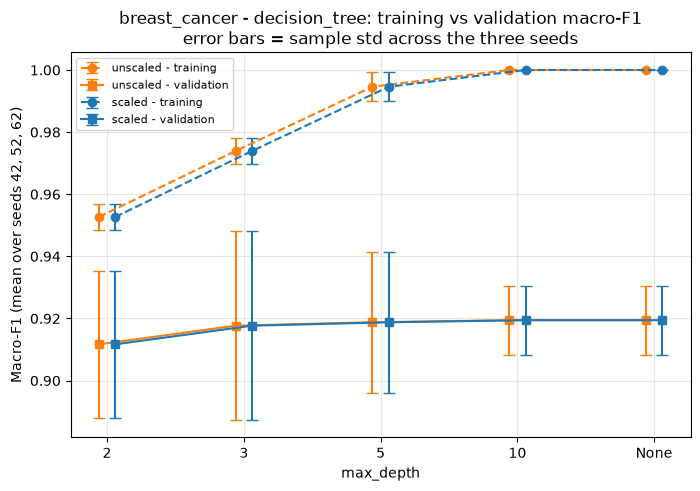

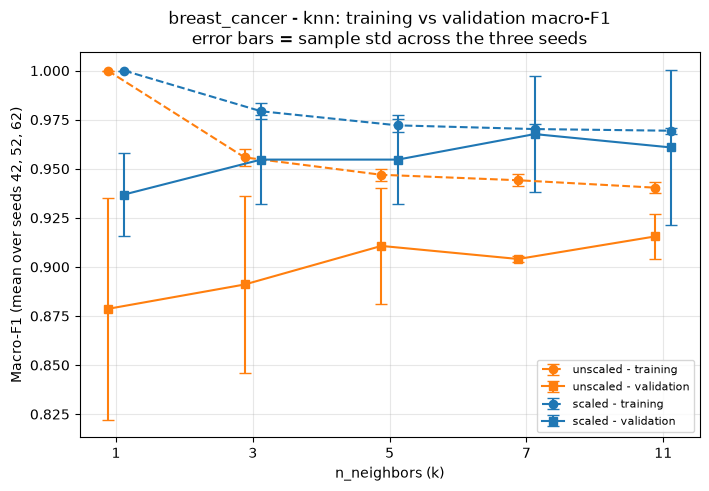

In [22]:
utils.plot_param_curve(summary, DATASET, "decision_tree", "max_depth", f"{DATASET}_tree_depth_comparison.png")
utils.plot_param_curve(summary, DATASET, "knn", "n_neighbors (k)", f"{DATASET}_knn_k_comparison.png")

**Interpretation.** **Selected configuration: `breast_cancer_knn_scaled_k7`** (mean validation macro-F1 = 0.9677, std = 0.0297; mean validation accuracy = 0.9708).

*Scaling.* Decision Tree results are identical with and without scaling (difference 0.0000), because a tree compares one feature at a time with a threshold, and rescaling only moves the threshold. KNN improved clearly with scaling, by +0.044 to +0.064 macro-F1 (for example k = 7: 0.9040 to 0.9677), because without scaling the distance is dominated by the area features. GaussianNB changed slightly (0.9369 unscaled vs 0.9248 scaled) because of its `var_smoothing` term, which is based on the largest feature variance.

*Tree depth.* Training macro-F1 rises from 0.953 (depth 2) to 1.000 (depth 10 and None), while validation macro-F1 only moves from 0.912 to 0.920. Depth 10 and None give identical results because the trees reach pure leaves before depth 10. A training/validation gap of about 0.08 shows overfitting.

*Neighbour count.* k = 1 memorises the training data (training F1 = 1.000) and has the largest gap (0.12 unscaled). Larger k lowers the training score and the gap. On scaled data, validation F1 peaks at k = 7 (0.968) and is slightly lower at k = 11 (0.961), so a larger k is not always better.

*Variability.* Seed standard deviations range up to 0.057 (unscaled k = 1). With only 57 validation rows, one sample changes accuracy by 1.75 percentage points, so small differences between the top configurations are not statistically significant. The standard deviation describes three overlapping repeated splits; it is not a confidence interval.

## 9. Evaluating the Selected Model on the Test Set
The selection above is frozen. Only the **seed-42 fitted instance** of the selected configuration is evaluated, once, using the seed-42 preprocessing. No refitting, no other candidates and no other seeds.
### 9.1 Final performance metrics

In [23]:
final_model = models_42[SELECTED]
final_rep = selected["representation"]
X_test_final = test_reps[final_rep]
print("Selected configuration:", SELECTED, "| representation:", final_rep, "| evaluation seed: 42")
print("Model:", final_model)

tm = utils.get_metrics(DATASET, final_model, X_test_final, y_test, "test")
final_table = pd.DataFrame([{
    "dataset": DATASET, "selected_configuration": SELECTED, "evaluation_seed": 42,
    "val_macro_f1_mean": selected["val_macro_f1_mean"], "val_macro_f1_std": selected["val_macro_f1_std"],
    "test_accuracy": tm["test_accuracy"], "test_macro_precision": tm["test_macro_precision"],
    "test_macro_recall": tm["test_macro_recall"], "test_macro_f1": tm["test_macro_f1"],
    "test_roc_auc": tm["test_roc_auc"], "test_undefined_metrics": tm["test_undefined_metrics"]}])
display(final_table.round(4))

y_test_pred = final_model.predict(X_test_final)
print(utils.classification_report(y_test, y_test_pred, labels=[0, 1],
                                  target_names=class_names, digits=4, zero_division=0))

Selected configuration: breast_cancer_knn_scaled_k7 | representation: scaled | evaluation seed: 42
Model: KNeighborsClassifier(metric='euclidean', n_neighbors=7)


,dataset,selected_configuration,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc,test_undefined_metrics
0,breast_cancer,breast_cancer_knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888,none


              precision    recall  f1-score   support

   malignant     1.0000    0.9286    0.9630        42
      benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



### 9.2 Confusion matrix (rows = Actual, columns = Predicted)
Class order is [0, 1] = [malignant, benign] and malignant is the positive class, so the first row holds TP and FN, and the second row holds FP and TN.

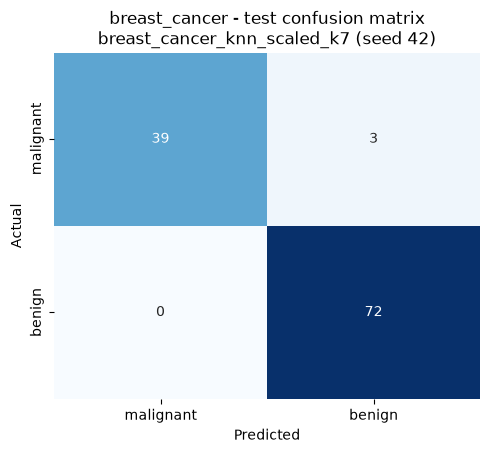

TP (malignant predicted malignant) = 39
FN (malignant predicted benign)    = 3   <- most dangerous error
FP (benign predicted malignant)    = 0
TN (benign predicted benign)       = 72


In [24]:
labels = [0, 1]
cm = utils.confusion_matrix(y_test, y_test_pred, labels=labels)
utils.plot_confusion(cm, class_names, f"{DATASET} - test confusion matrix\n{SELECTED} (seed 42)",
                     f"{DATASET}_confusion_matrix.png")
TP, FN = cm[0, 0], cm[0, 1]     # actual malignant row
FP, TN = cm[1, 0], cm[1, 1]     # actual benign row
print(f"TP (malignant predicted malignant) = {TP}")
print(f"FN (malignant predicted benign)    = {FN}   <- most dangerous error")
print(f"FP (benign predicted malignant)    = {FP}")
print(f"TN (benign predicted benign)       = {TN}")

In [25]:
manual = utils.manual_metrics(cm, 0, class_names)
display(pd.DataFrame([manual]).round(4))

report = utils.classification_report(y_test, y_test_pred, labels=labels, target_names=class_names,
                                     output_dict=True, zero_division=0)["malignant"]
print("classification_report, malignant row: precision = %.4f, recall = %.4f, f1 = %.4f"
      % (report["precision"], report["recall"], report["f1-score"]))
print("Manual values match the report:",
      np.allclose([manual["precision = TP/(TP+FP)"], manual["recall = TP/(TP+FN)"], manual["F1 = 2PR/(P+R)"]],
                  [report["precision"], report["recall"], report["f1-score"]]))

,class,TP,FP,FN,TN,precision = TP/(TP+FP),recall = TP/(TP+FN),F1 = 2PR/(P+R)
0,0 (malignant),39,0,3,72,1.0,0.9286,0.963


classification_report, malignant row: precision = 1.0000, recall = 0.9286, f1 = 0.9630
Manual values match the report: True


**Interpretation** The selected seed-42 model reaches a test accuracy of 0.9737, macro-precision of 0.9800, macro-recall of 0.9643, macro-F1 of 0.9713 and ROC-AUC of 0.9888. The test macro-F1 (0.971) is very close to the mean validation macro-F1 (0.968 ± 0.030), so the validation estimate was realistic. The selection was not changed after seeing the test results.

Confusion matrix (malignant = positive): TP = 39 malignant cases correctly detected, FN = 3 malignant cases predicted as benign, FP = 0 benign cases predicted as malignant, TN = 72 benign cases correctly identified. Manual check for the malignant class: precision = 39 / (39 + 0) = 1.0000, recall = 39 / (39 + 3) = 0.9286, F1 = 2 × 1.0000 × 0.9286 / (1.0000 + 0.9286) = 0.9630. These values match the malignant row of the classification report (not the macro averages).

### 9.3 ROC curve

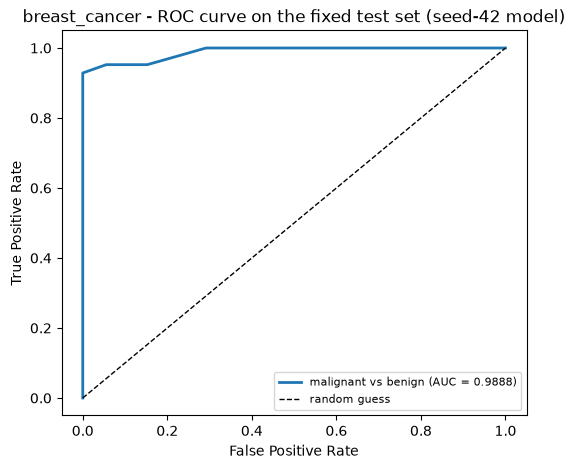

,curve,AUC
0,malignant (class 0) vs benign,0.9888


In [26]:
aucs = utils.plot_roc(DATASET, final_model, X_test_final, y_test, class_names, f"{DATASET}_roc_curve.png")
display(pd.DataFrame({"curve": list(aucs.keys()), "AUC": [round(v, 4) for v in aucs.values()]}))

### 9.4 Error interpretation

In [27]:
wrong = utils.wrong_predictions(final_model, X_test_final, y_test, class_names)
print("Misclassified test samples:", len(wrong), "of", len(y_test))
display(wrong)

Misclassified test samples: 3 of 114


,original_row_index,actual,predicted,P(class 0),P(class 1)
0,41,0 (malignant),1 (benign),0.4286,0.5714
1,73,0 (malignant),1 (benign),0.1429,0.8571
2,205,0 (malignant),1 (benign),0.1429,0.8571


**Interpretation** *ROC* The malignant-vs-benign ROC curve has an AUC of 0.9888, so the model ranks almost every malignant case above every benign case. A sample is labelled malignant when P(malignant) is at least the decision threshold (0.5 by default). Lowering the threshold labels more samples as malignant: false negatives decrease, but false positives can increase. Raising it has the opposite effect. The ROC curve shows this trade-off for every threshold. No threshold was chosen or tuned on the test set.

*Errors* All three test errors are false negatives (malignant predicted as benign), which is the most serious error in a cancer setting. Row 41 has P(malignant) = 0.43 (3 of its 7 nearest neighbours are malignant), so it lies close to the class boundary. Rows 73 and 205 have P(malignant) = 0.14 (1 of 7 neighbours), so in the scaled feature space they look like typical benign tumours. *Limitations:* the validation subsets are small (57 rows), the three training/validation repetitions overlap, and only the predeclared seed-42 model was tested once on 114 rows, so the test result has its own sampling uncertainty.

## 10. K-Means Clustering
K-Means is unsupervised: it is fitted on training **features only** (`y_train` is never passed to `fit`). n_clusters = 2 (fixed from the number of classes, not searched), `random_state=seed`, `n_init=10` (10 internal initialisations inside one fit, not extra experiments). 2 representations x 3 seeds = 6 fits. K-Means cluster IDs are not class labels.
### 10.1 Fit the clustering model

In [28]:
N_CLUSTERS = 2
km_runs, kmeans_42 = utils.run_kmeans(DATASET, reps, splits, N_CLUSTERS)
print("K-Means fits:", len(km_runs))
display(km_runs.round(4))

km_summary = utils.summarize_kmeans(km_runs)
print("Across-seed summary (one row per representation). Raw inertia is NOT comparable "
      "between scaled and unscaled spaces because the units differ.")
display(km_summary.round(4))

K-Means fits: 6


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_silhouette_note,val_cluster_counts
0,breast_cancer,breast_cancer_kmeans_unscaled_c2_s42,42,unscaled,2,10,5.156538e+07,0.3995,0.6387,ok,"[46, 11]"
1,breast_cancer,breast_cancer_kmeans_scaled_c2_s42,42,scaled,2,10,7.918810e+03,0.4516,0.2854,ok,"[43, 14]"
2,breast_cancer,breast_cancer_kmeans_unscaled_c2_s52,52,unscaled,2,10,4.919078e+07,0.6122,0.6975,ok,"[42, 15]"
3,breast_cancer,breast_cancer_kmeans_scaled_c2_s52,52,scaled,2,10,8.003001e+03,0.5586,0.3750,ok,"[18, 39]"
4,breast_cancer,breast_cancer_kmeans_unscaled_c2_s62,62,unscaled,2,10,5.305649e+07,0.5013,0.6958,ok,"[44, 13]"
5,breast_cancer,breast_cancer_kmeans_scaled_c2_s62,62,scaled,2,10,7.922515e+03,0.7336,0.2758,ok,"[36, 21]"


Across-seed summary (one row per representation). Raw inertia is NOT comparable between scaled and unscaled spaces because the units differ.


,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,n_valid_silhouette_seeds,n_seeds
0,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.5043,0.1064,0.6773,0.0334,3,3
1,breast_cancer,scaled,7.948109e+03,4.757430e+01,0.5813,0.1424,0.3121,0.0547,3,3


**Interpretation** Unscaled K-Means has a mean validation ARI of 0.504 (std 0.106) and a mean silhouette of 0.677. Scaled K-Means has a mean ARI of 0.581 (std 0.142) and a mean silhouette of 0.312. The silhouette was defined for all three seeds in both representations. Inertia is not compared across representations because it is measured in different units (about 5 x 10^7 unscaled vs about 8 x 10^3 scaled).

### 10.2 Final cluster evaluation on the fixed test set (seed-42 models, no new fits)
Both representations are evaluated; neither is selected by its test score. True labels are used only to evaluate the clusters (ARI and contingency tables), never to fit or rename them.

In [29]:
km_test_rows = []
for rep in utils.REPRESENTATIONS:
    Xt = test_reps[rep]
    clusters = kmeans_42[rep].predict(Xt)
    sil, note = utils.safe_silhouette(Xt, clusters)
    counts = np.bincount(clusters, minlength=N_CLUSTERS).tolist()
    km_test_rows.append({"dataset": DATASET, "representation": rep, "seed": 42,
                         "test_cluster_counts": str(counts),
                         "test_ari": utils.adjusted_rand_score(y_test, clusters),
                         "test_silhouette": sil, "silhouette_note": note})
    table = pd.crosstab(pd.Series(y_test.map(lambda c: f"{c} ({class_names[c]})").values, name="true class"),
                        pd.Series(clusters, name="cluster ID"))
    print(f"\nClass-versus-cluster contingency table - {DATASET}, {rep}, seed 42, test set:")
    display(table)

km_test = pd.DataFrame(km_test_rows)
display(km_test.round(4))


Class-versus-cluster contingency table - breast_cancer, unscaled, seed 42, test set:


cluster ID,0,1
true class,,
0 (malignant),14,28
1 (benign),72,0



Class-versus-cluster contingency table - breast_cancer, scaled, seed 42, test set:


cluster ID,0,1
true class,,
0 (malignant),5,37
1 (benign),69,3


,dataset,representation,seed,test_cluster_counts,test_ari,test_silhouette,silhouette_note
0,breast_cancer,unscaled,42,"[86, 28]",0.5585,0.7120,ok
1,breast_cancer,scaled,42,"[74, 40]",0.7354,0.3251,ok


### 10.3 Visualise the clusters

Two original features chosen from seed-42 TRAINING data: worst concave points and worst radius


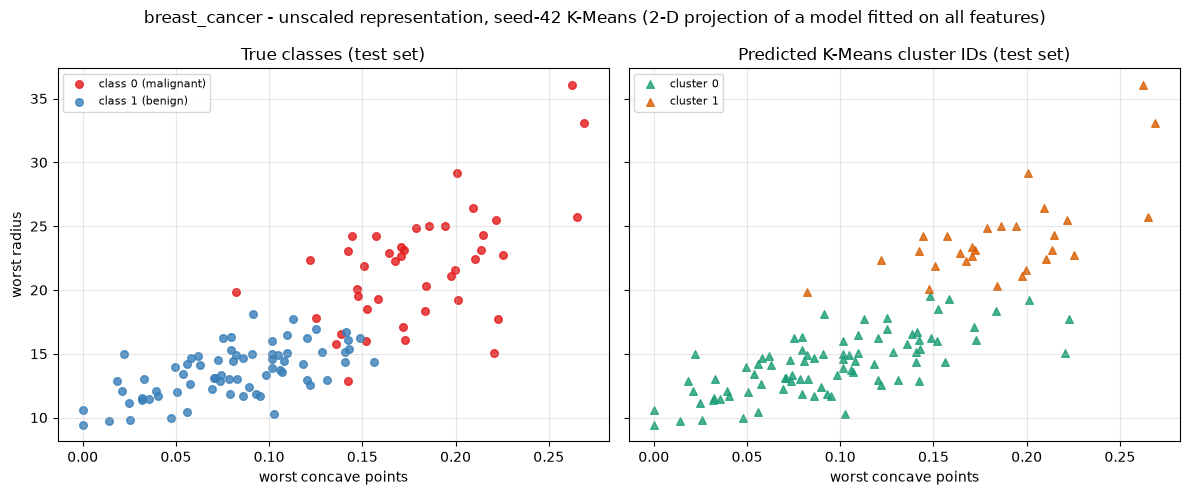

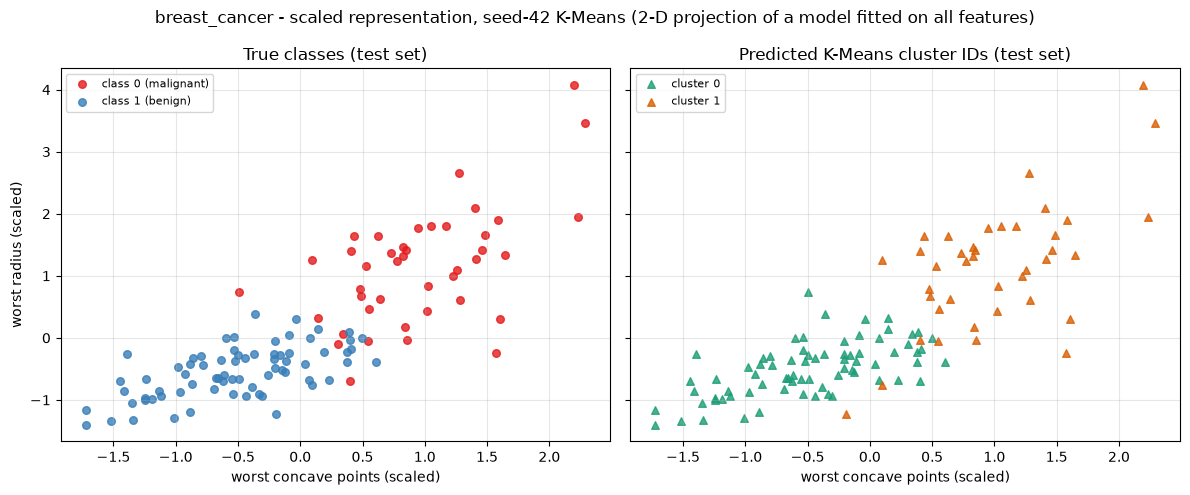

In [30]:
f1_name, f2_name = utils.choose_two_features(splits[42]["X_train"], splits[42]["y_train"])
print("Two original features chosen from seed-42 TRAINING data:", f1_name, "and", f2_name)
for rep in utils.REPRESENTATIONS:
    Xt = test_reps[rep]
    clusters = kmeans_42[rep].predict(Xt)
    utils.plot_class_vs_cluster(Xt, y_test, clusters, f1_name, f2_name, DATASET, rep, class_names,
                                f"{DATASET}_kmeans_{rep}_class_vs_cluster.png")

**Interpretation** *Test(seed 42)* Unscaled: cluster sizes 86 and 28, ARI = 0.559. Cluster 1 contains only malignant cases (28), while cluster 0 contains all 72 benign cases plus 14 malignant ones. The unscaled partition is mainly a split on tumour size, because the area features dominate the distance. Scaled: cluster sizes 74 and 40, ARI = 0.735. Cluster 1 holds 37 malignant and 3 benign cases, and cluster 0 holds 69 benign and 5 malignant cases, so the clusters agree better with the classes. The unscaled silhouette is higher (0.712 vs 0.325) only because, in raw units, one or two large features create a very clear separation. Silhouette depends on the feature space, so this is not proof of a better model.

*Plots.* `worst concave points` and `worst radius` were chosen from the seed-42 training data (the highest ANOVA F-score, then the next strong feature with |r| < 0.8). The plots show only a 2-D projection of models fitted on all 30 features.

*Information available.* K-Means received only the training features and minimised within-cluster distances; it never saw `y_train`, and its cluster IDs are arbitrary. The classifiers were fitted with the true labels, so they could learn the malignant/benign boundary directly. The labels were used for K-Means only afterwards, for evaluation.

## Export of results(Section 12)
This dataset's rows are written into the six combined CSV files in `results/`. Each file has a `dataset` column. Rows written by the other notebook are kept, so after running both notebooks every file contains both datasets.

In [31]:
exports = {
    "classifier_runs.csv": runs,
    "classifier_summary.csv": summary,
    "classifier_test.csv": final_table,
    "kmeans_runs.csv": km_runs,
    "kmeans_summary.csv": km_summary,
    "kmeans_test.csv": km_test,
}
for name, df in exports.items():
    path, total = utils.save_combined_csv(df, name)
    print(f"{path}: {len(df)} rows for {DATASET}, {total} rows in the combined file")

check = pd.read_csv("results/classifier_runs.csv", keep_default_na=False)
print("\nmax_depth values in classifier_runs.csv:",
      sorted(check[check["parameter"] == "max_depth"]["parameter_value"].unique()))

results\classifier_runs.csv: 66 rows for breast_cancer, 66 rows in the combined file
results\classifier_summary.csv: 22 rows for breast_cancer, 22 rows in the combined file
results\classifier_test.csv: 1 rows for breast_cancer, 1 rows in the combined file
results\kmeans_runs.csv: 6 rows for breast_cancer, 6 rows in the combined file
results\kmeans_summary.csv: 2 rows for breast_cancer, 2 rows in the combined file
results\kmeans_test.csv: 2 rows for breast_cancer, 2 rows in the combined file

max_depth values in classifier_runs.csv: ['10', '2', '3', '5', 'None']
